# Fútbol y apuestas: ¿se le puede ganar a la casa?
## Proyecto final — Gerencia y almacenamiento en Big Data
### Pipeline integral de Big Data con Machine Learning, almacenamiento híbrido y dashboard contenerizado

**Autor:** Juan Felipe Vanegas Silva · Fundación Universitaria Los Libertadores
**Video de sustentación:** *PEGAR AQUÍ EL ENLACE NO LISTADO*

**Dataset:** 238.858 partidos de 38 ligas (2000–2026) con resultados, estadísticas y cuotas de casas de apuestas
(**Football-Data.co.uk**), 273.972 ratings Elo (**ClubElo**) y 656.301 valoraciones de jugadores, partidos y clubes de
**Transfermarkt**: **1.258.950 registros crudos** de tres fuentes públicas.

**Metodología:** CRISP-DM de punta a punta (incluye Modeling y Evaluation).

| # | Sección | Fase CRISP-DM |
|---|---|---|
| 1 | Business Understanding y dataset | Business Understanding |
| 2 | Decisión de arquitectura: pandas o Spark | — |
| 3 | Exploración inicial y calidad de datos | Data Understanding |
| 4 | ETL: limpieza, normalización, enriquecimiento, agregación | Data Preparation |
| 5 | Análisis exploratorio, visualizaciones y OLAP | Data Understanding |
| 6 | Machine Learning | Modeling |
| 7 | Evaluación e interpretación | Evaluation |
| 8 | Insights en MongoDB | Deployment |
| 9 | Reporte PDF | Deployment |
| 10 | Conclusiones | — |

> Este notebook usa las mismas funciones de `src/` que ejecuta el servicio `procesamiento` de Docker, así no hay dos
> versiones del pipeline. Se ejecuta completo dentro del contenedor (ver README, sección *Ejecutar el notebook*).

In [1]:
import json, os, sys, time, platform
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

import config as C
import descargar_datos, etl, modelo, graficas, mongo_insights, reporte_pdf

# graficas.py fija el backend "Agg" (y el contenedor define MPLBACKEND=Agg) para generar PNG sin pantalla;
# en el notebook se vuelve al backend inline para que las figuras queden embebidas en las salidas.
%matplotlib inline

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
graficas.estilo()
print("Raíz del proyecto:", RAIZ)
print("Python", platform.python_version(), "| pandas", pd.__version__, "| MongoDB en", f"{C.MONGO_HOST}:{C.MONGO_PORT}")

Raíz del proyecto: /proyecto
Python 3.13.18 | pandas 3.0.6 | MongoDB en mongo:27017


---
## 1. Business Understanding

### 1.1 Problema de negocio
Las casas de apuestas publican cuotas que, en el fondo, son **probabilidades** de cada resultado con un margen para
ellas. Millones de personas apuestan creyendo que "saben más que la casa". La pregunta de negocio es:

> **¿Se puede predecir el resultado de un partido de fútbol con datos públicos tan bien como las casas de apuestas, y
> alcanza eso para obtener un beneficio apostando?**

Responderla sirve a tres públicos: al **apostador** (¿vale la pena?), a **clubes y analistas** (¿qué variables
explican los resultados?) y a un **equipo de datos** (¿cómo se construye un producto de pronósticos reproducible?).

### 1.2 Preguntas específicas
1. **¿Sigue existiendo la ventaja de jugar en casa?** ¿Cómo cambió en 26 años y qué pasó con los estadios vacíos (COVID-19)?
2. **¿Qué tan eficientes son las casas de apuestas?** ¿Están bien calibradas sus probabilidades y cuánto margen cobran?
3. **¿Qué variables explican el resultado?** Elo, forma reciente, valor de la plantilla, descanso, liga…
4. **¿Pesa el dinero?** ¿Gana más quien tiene la plantilla más cara (Transfermarkt)?
5. **¿Puede un modelo igualar a la casa** y obtener ROI positivo con una estrategia de apuestas de valor?

### 1.3 Tarea de Machine Learning y criterio de éxito
- **Tarea:** clasificación multiclase del resultado (**Local / Empate / Visitante**) con información disponible
  **antes** del partido.
- **Líneas base:** (a) *siempre gana el local* (la clase mayoritaria) y (b) *gana el favorito de la casa*.
- **Criterios de éxito definidos antes de modelar:**
  1. Superar la línea base ingenua en **al menos 10 % de F1 macro**.
  2. Lograr un **log-loss igual o menor que el de las probabilidades de la casa** (el mercado es el rival real).
  3. *(Deseable)* ROI positivo en una simulación de apuestas sobre temporadas no vistas.

### 1.4 Descripción del dataset y evidencia de la descarga
Los archivos grandes **no** van en la entrega: `src/descargar_datos.py` los deja en `data/raw/` y registra URL, fecha,
filas, columnas y peso (en disco y en memoria) en `data/raw/registro_descarga.json`.

| Fuente | Qué aporta | Por qué |
|---|---|---|
| Football-Data.co.uk (vía repositorio `xgabora/Club-Football-Match-Data`) | Resultados, estadísticas y cuotas de Bet365 y de ~17 casas | Fuente de referencia del análisis deportivo de apuestas |
| ClubElo | Ratings Elo quincenales de clubes | Medida histórica de fuerza |
| Transfermarkt (`dcaribou/transfermarkt-datasets`) | Partidos con id de club y valor de mercado de jugadores | Dinero/calidad individual; obliga a homologar nombres entre fuentes |

> El sitio oficial football-data.co.uk cerraba la conexión desde el equipo de trabajo (ver README, *Problemas de
> infraestructura*), por eso se usa el espejo público en GitHub que reúne los mismos CSV de Football-Data.co.uk.

In [2]:
registro = descargar_datos.main(forzar=False)
tabla_fuentes = pd.DataFrame(registro).T[["fuente", "url", "fecha_descarga", "filas", "columnas", "peso_disco_mb", "peso_memoria_mb"]]
display(tabla_fuentes)
print(f"TOTAL: {tabla_fuentes['filas'].sum():,} filas crudas | {tabla_fuentes['peso_disco_mb'].sum():.1f} MB en disco | "
      f"{tabla_fuentes['peso_memoria_mb'].sum():.1f} MB en memoria")

[ok] Matches.csv ya existe (45.4 MB)


[ok] EloRatings.csv ya existe (11.1 MB)


[ok] games.csv.gz ya existe (5.0 MB)


[ok] clubs.csv.gz ya existe (0.1 MB)
[ok] competitions.csv.gz ya existe (0.0 MB)
[ok] player_valuations.csv.gz ya existe (7.2 MB)


Total de filas crudas: 1,258,950


,fuente,url,fecha_descarga,filas,columnas,peso_disco_mb,peso_memoria_mb
Matches.csv,"Football-Data.co.uk (resultados, estadísticas ...",https://raw.githubusercontent.com/xgabora/Club...,2026-11-07T21:36:51+00:00,238858,48,45.370,100.280
EloRatings.csv,ClubElo (ratings Elo quincenales de clubes) ví...,https://raw.githubusercontent.com/xgabora/Club...,2026-11-07T21:36:53+00:00,273972,4,11.060,14.620
games.csv.gz,Transfermarkt (partidos con identificadores de...,https://pub-e682421888d945d684bcae8890b0ec20.r...,2026-11-07T21:37:27+00:00,88958,23,5.000,37.130
clubs.csv.gz,Transfermarkt (clubes) vía dcaribou/transferma...,https://pub-e682421888d945d684bcae8890b0ec20.r...,2026-11-07T21:37:28+00:00,796,17,0.050,0.260
competitions.csv.gz,Transfermarkt (competiciones) vía dcaribou/tra...,https://pub-e682421888d945d684bcae8890b0ec20.r...,2026-11-07T21:37:28+00:00,65,11,0.000,0.020
player_valuations.csv.gz,Transfermarkt (historial de valor de mercado d...,https://pub-e682421888d945d684bcae8890b0ec20.r...,2026-11-07T21:37:29+00:00,656301,6,7.200,49.330


TOTAL: 1,258,950 filas crudas | 68.7 MB en disco | 201.6 MB en memoria


---
## 2. Decisión de arquitectura: ¿pandas o Spark?

Se retoman los criterios de la Actividad 4: **volumen frente a la RAM**, **tipo de trabajo** (por fila o por archivo),
**costo de arranque** y **complejidad de despliegue**. Primero, los recursos reales y los tiempos de pandas medidos aquí
mismo (dentro del contenedor):

In [3]:
def ram_total_gb():
    try:
        import psutil
        return psutil.virtual_memory().total / 1e9
    except ImportError:
        try:
            with open("/proc/meminfo") as f:
                return int(f.readline().split()[1]) / 1e6
        except OSError:
            return float("nan")

limite_contenedor = None
for ruta in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
    if os.path.exists(ruta):
        valor = open(ruta).read().strip()
        limite_contenedor = None if valor == "max" or int(valor) > 1e15 else int(valor) / 1e9

t0 = time.perf_counter(); partidos_crudos = pd.read_csv(C.DATA_RAW / "Matches.csv", low_memory=False); t_csv = time.perf_counter() - t0
t0 = time.perf_counter(); valoraciones = pd.read_csv(C.DATA_RAW / "player_valuations.csv.gz"); t_val = time.perf_counter() - t0
mem_crudo = partidos_crudos.memory_usage(deep=True).sum() / 1e6
recursos = pd.Series({
    "CPU lógicos": os.cpu_count(), "RAM del equipo (GB)": round(ram_total_gb(), 1),
    "Límite de memoria del contenedor (GB)": limite_contenedor or "sin límite",
    "Matches.csv: filas": f"{len(partidos_crudos):,}", "Matches.csv: lectura (s)": round(t_csv, 2),
    "Matches.csv: memoria (MB)": round(mem_crudo, 1),
    "player_valuations: filas": f"{len(valoraciones):,}", "player_valuations: lectura (s)": round(t_val, 2),
})
display(recursos.to_frame("valor"))

,valor
CPU lógicos,4
RAM del equipo (GB),10.300
Límite de memoria del contenedor (GB),6.442
Matches.csv: filas,"238,858"
Matches.csv: lectura (s),1.820
Matches.csv: memoria (MB),100.300
player_valuations: filas,"656,301"
player_valuations: lectura (s),0.890


**Benchmark pandas vs. Spark sobre los mismos datos.** Spark **no** está en la imagen de Docker (es la decisión que
se justifica aquí), así que el benchmark completo se ejecuta en el equipo del autor con `python src/benchmark_spark.py`
(Spark 4.2, `local[*]`, `spark.driver.memory=4g`, `spark.sql.shuffle.partitions = 2 × núcleos`) y su resultado queda
en `reports/benchmark_pandas_spark.json`:

In [4]:
ruta_bench = C.REPORTS / "benchmark_pandas_spark.json"
if ruta_bench.exists():
    bench = json.loads(ruta_bench.read_text(encoding="utf-8"))
    print("Máquina:", bench["maquina"], "| fecha:", bench["fecha"])
    filas = []
    for operacion in ["lectura_csv_partidos_s", "agregacion_liga_anio_s", "agregacion_y_join_valoraciones_s"]:
        filas.append({"operación": operacion, "pandas (s)": bench["pandas"].get(operacion),
                      "Spark (s)": bench.get("spark", {}).get(operacion, "—")})
    filas.append({"operación": "arranque de la sesión", "pandas (s)": 0, "Spark (s)": bench.get("spark", {}).get("arranque_sesion_s", "—")})
    display(pd.DataFrame(filas))
    if "error" in bench.get("spark", {}):
        print("Spark no pudo arrancar en esa ejecución:", bench["spark"]["error"][:200])
else:
    print("Aún no se ha ejecutado src/benchmark_spark.py en el equipo del autor; se usan solo las mediciones de pandas.")

Máquina: {'sistema': 'Windows-11-10.0.26200-SP0', 'cpu_logicos': 4, 'ram_gb': 21.3, 'python': '3.13.4', 'pandas': '3.0.6'} | fecha: 2026-11-07 17:43


,operación,pandas (s),Spark (s)
0,lectura_csv_partidos_s,1.841,1.944
1,agregacion_liga_anio_s,0.548,0.864
2,agregacion_y_join_valoraciones_s,0.076,1.452
3,arranque de la sesión,0.000,18.600


**Decisión: pandas.** Con datos propios:

| Criterio | Evidencia | Conclusión |
|---|---|---|
| Volumen vs. RAM | ~1,26 M filas crudas; el dataset limpio ocupa ~**80 MB** en memoria con tipos optimizados, menos del 1 % de la RAM | Cabe de sobra en un proceso: no es Big Data por volumen |
| Tiempos | Leer el CSV más grande toma ~1–2 s y las agregaciones fracciones de segundo | No hay cuello de botella que paralelizar |
| Costo de arranque | Una SparkSession tarda varios segundos solo en arrancar (Actividad 4) y añade JVM | Para este volumen Spark sería más lento de punta a punta |
| Tipo de trabajo | El cálculo más pesado es el **Elo secuencial** (cada partido depende del anterior) | Es intrínsecamente secuencial: Spark no lo acelera |
| Despliegue | Spark en Docker exige Java (~300 MB más en la imagen) y configuración de memoria | Más complejidad sin beneficio |

**Técnicas de pandas para manejar el volumen:** tipos optimizados (`category`, `Int8`, `float32`: el dataset baja de
~91 MB a ~37 MB tras la normalización), lectura de CSV comprimidos `.gz` sin descomprimir, **Parquet** columnar para
todas las salidas (21 MB frente a 45 MB del CSV, y se lee en ~0,15 s) y lectura selectiva de columnas en el dashboard.
Si el proyecto creciera a datos por evento (millones de filas por temporada, p. ej. tracking), la decisión cambiaría a Spark.

---
## 3. Data Understanding: exploración inicial (antes de limpiar)
### 3.1 Estructura, tipos, nulos y duplicados

In [5]:
print("Forma:", partidos_crudos.shape)
print("Tipos:", partidos_crudos.dtypes.value_counts().to_dict())
nulos = (partidos_crudos.isna().mean() * 100).round(2).sort_values(ascending=False)
display(nulos[nulos > 0].to_frame("% nulos").T)
print("Filas duplicadas exactas:", partidos_crudos.duplicated().sum())
print("Duplicados por (liga, fecha, local, visitante):", partidos_crudos.duplicated(["Division", "MatchDate", "HomeTeam", "AwayTeam"]).sum())
display(partidos_crudos.head(3))

Forma: (238858, 48)
Tipos: {dtype('float64'): 41, <StringDtype(na_value=nan)>: 7}


,MatchTime,C_LTA,C_VHD,C_VAD,C_LTH,C_HTB,C_PHB,HomeTarget,AwayTarget,HomeFouls,AwayFouls,HomeCorners,AwayCorners,AwayShots,HomeShots,AwayRed,HomeRed,AwayYellow,HomeYellow,AwayElo,HomeElo,Under25,Over25,MaxUnder25,MaxOver25,HandiAway,HandiHome,HandiSize,HTHome,HTResult,HTAway,MaxAway,MaxHome,MaxDraw,OddHome,OddAway,OddDraw,Form3Home,Form5Home,Form3Away,Form5Away
% nulos,55.050,52.860,52.860,52.860,52.860,52.860,52.860,49.060,49.060,49.040,49.040,48.880,48.880,48.720,48.720,46.580,46.580,46.580,46.580,37.270,37.240,34.400,34.400,34.400,34.400,31.040,31.030,30.920,22.850,22.850,22.850,11.570,11.570,11.570,1.270,1.270,1.270,0.640,0.640,0.640,0.640


Filas duplicadas exactas: 0
Duplicados por (liga, fecha, local, visitante): 0


,Division,MatchDate,MatchTime,HomeTeam,AwayTeam,HomeElo,AwayElo,Form3Home,Form5Home,Form3Away,Form5Away,FTHome,FTAway,FTResult,HTHome,HTAway,HTResult,HomeShots,AwayShots,HomeTarget,AwayTarget,HomeFouls,AwayFouls,HomeCorners,AwayCorners,HomeYellow,AwayYellow,HomeRed,AwayRed,OddHome,OddDraw,OddAway,MaxHome,MaxDraw,MaxAway,Over25,Under25,MaxOver25,MaxUnder25,HandiSize,HandiHome,HandiAway,C_LTH,C_LTA,C_VHD,C_VAD,C_HTB,C_PHB
0,F1,2000-07-28,NaN,Marseille,Troyes,"1,686.340","1,586.570",0.000,0.000,0.000,0.000,3.000,1.000,H,2.000,1.000,H,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.650,3.300,4.300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,F1,2000-07-28,NaN,Paris SG,Strasbourg,"1,714.890","1,642.510",0.000,0.000,0.000,0.000,3.000,1.000,H,1.000,1.000,D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.600,3.400,4.600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,F2,2000-07-28,NaN,Wasquehal,Nancy,"1,465.080","1,633.800",0.000,0.000,0.000,0.000,0.000,1.000,A,0.000,1.000,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
display(partidos_crudos.describe().T[["count", "mean", "std", "min", "50%", "max"]])

,count,mean,std,min,50%,max
HomeElo,"149,898.000","1,532.436",152.776,"1,103.130","1,513.210","2,107.480"
AwayElo,"149,829.000","1,532.476",152.789,"1,103.130","1,513.330","2,107.480"
Form3Home,"237,334.000",3.986,2.378,0.000,4.000,9.000
Form5Home,"237,323.000",6.722,3.258,0.000,7.000,15.000
Form3Away,"237,335.000",4.203,2.394,0.000,4.000,9.000
Form5Away,"237,324.000",6.929,3.271,0.000,7.000,15.000
FTHome,"238,854.000",1.489,1.258,0.000,1.000,10.000
FTAway,"238,854.000",1.153,1.113,0.000,1.000,13.000
HTHome,"184,278.000",0.658,0.813,0.000,0.000,7.000
HTAway,"184,278.000",0.505,0.717,0.000,0.000,7.000


Lo que salta a la vista en `describe()`: **cuotas de 0** (imposibles: una cuota paga al menos lo apostado), un
**hándicap de −99,9**, un partido con **145 faltas** de un equipo, **9 expulsados** en otro y cuotas máximas de **301**.
Además, el **Elo falta en el 37 %** de los partidos (ligas que ClubElo no cubre) y las estadísticas de juego en ~49 %.

### 3.2 Tabla de problemas de calidad detectados

In [7]:
diagnostico = etl.diagnostico_calidad(partidos_crudos)
display(diagnostico)
tm_partidos = pd.read_csv(C.DATA_RAW / "games.csv.gz", low_memory=False)
display(etl.diagnostico_transfermarkt(valoraciones, tm_partidos))

,problema,tipo,registros,porcentaje,accion
0,Espacios sobrantes en nombres de equipo,Formato,43,0.018,Recortar con str.strip()
1,"Cuotas 1X2 menores a 1,01 (imposibles: pagaría...",Validez,7,0.003,Anular las 3 cuotas del partido
2,"Margen de la casa fuera de [0 %, 30 %] (suma d...",Consistencia,15,0.006,Anular las 3 cuotas del partido
3,"Cuota máxima > 3 veces la de Bet365 o < 1,01 (...",Validez,32,0.013,Anular cuotas máximas
4,"Cuotas máximas de goles > 20 (Over/Under 2,5)",Validez,2,0.001,Anular
5,Hándicap asiático fuera de ±10 goles (p. ej. −...,Validez,3,0.001,Anular hándicap y sus cuotas
6,"Cuotas de hándicap fuera de [1,01; 20]",Validez,6,0.003,Anular hándicap y sus cuotas
7,Más tiros al arco que tiros totales,Consistencia,17,0.007,Anular tiros y tiros al arco del partido
8,Más de 60 faltas de un equipo (máx. real ≈ 35),Atípico,2,0.001,Anular faltas
9,Más de 5 expulsados de un equipo (el partido s...,Validez,1,0.000,Anular tarjetas rojas


,problema,registros,tipo,accion
0,Valoraciones con valor de mercado 0 €,1,Validez,Excluir de la suma de plantilla
1,"Valoraciones duplicadas (jugador, fecha)",0,Unicidad,Conservar la última
2,Valoraciones con club 'Unknown',3199,Completitud,"Se usa el id del club, no el nombre"
3,Partidos de Transfermarkt duplicados (game_id),0,Unicidad,Eliminar duplicados
4,Partidos de Transfermarkt sin nombre de club,122,Completitud,Se usa el id del club


In [8]:
# Evidencia concreta de algunos problemas
print("Partidos sin resultado (suspendidos o no jugados):")
display(partidos_crudos[partidos_crudos["FTResult"].isna()][["Division", "MatchDate", "HomeTeam", "AwayTeam", "FTHome", "FTAway", "OddHome"]])
print("Hándicap imposible y cuotas en cero:")
display(partidos_crudos[(partidos_crudos["HandiSize"].abs() > 10) | (partidos_crudos["OddHome"] < 1.01)]
        [["Division", "MatchDate", "HomeTeam", "AwayTeam", "OddHome", "OddDraw", "OddAway", "HandiSize"]].head(8))

Partidos sin resultado (suspendidos o no jugados):


,Division,MatchDate,HomeTeam,AwayTeam,FTHome,FTAway,OddHome
112580,G1,2015-05-10,Niki Volos,OFI,NaN,NaN,NaN
130377,BRA,2016-11-12,Chapecoense-SC,Atletico-MG,NaN,NaN,2.850
159189,G1,2019-03-17,Panathinaikos,Olympiakos,NaN,NaN,5.250
233555,F2,2025-12-05,Bastia,Red Star,NaN,NaN,2.500


Hándicap imposible y cuotas en cero:


,Division,MatchDate,HomeTeam,AwayTeam,OddHome,OddDraw,OddAway,HandiSize
38773,N1,2007-02-10,AZ Alkmaar,Willem II,1.120,7.000,13.000,-99.900
50081,SC0,2008-10-25,Hamilton,Rangers,10.000,4.750,1.330,12.500
84170,E3,2013-01-12,Chesterfield,Northampton,0.000,3.600,3.250,-0.300
88162,E1,2013-04-27,Blackpool,Derby,0.000,3.400,3.400,-0.300
95852,SC2,2014-01-11,Rangers,East Fife,1.080,10.000,26.000,-99.900
110731,E2,2015-03-28,Sheffield United,Crewe,0.000,5.250,10.000,-1.300
157309,E1,2019-02-02,Brentford,Blackburn,0.000,3.750,4.200,-0.800
157338,SC1,2019-02-02,Inverness C,Partick,0.000,3.500,4.500,-0.800


Hallazgo con historia: el partido brasileño sin resultado es **Chapecoense vs. Atlético-MG del 12/11/2016**, que no se
jugó tras la tragedia aérea del Chapecoense, y el griego es el **Panathinaikos vs. Olympiakos de 2019**, suspendido.

**Fuga de información detectada:** las columnas `C_*` del espejo son probabilidades de clúster que su autor calculó con
las **estadísticas del mismo partido** (tiros, tarjetas). Usarlas para predecir sería hacer trampa: se eliminan.

---
## 4. Data Preparation: ETL con las 4 técnicas

`etl.ejecutar_etl()` aplica en orden **limpieza → normalización → enriquecimiento → agregación** y anota cada paso con
filas/valores **antes, después y afectados**. Se corre una vez (≈ 1–2 min) y luego se muestra la evidencia de cada técnica.

In [9]:
t0 = time.perf_counter()
resultado_etl = etl.ejecutar_etl(verbose=False)
print(f"ETL completo en {time.perf_counter() - t0:.1f} s")
partidos = resultado_etl["partidos"]
largo = resultado_etl["largo"]
pasos = resultado_etl["registro"].tabla()

ETL completo en 115.9 s


### 4.1 Limpieza

In [10]:
display(pasos[pasos["tecnica"] == "Limpieza"])
print("Mismo partido con hándicap −99,9 ANTES y DESPUÉS de limpiar:")
fila = partidos_crudos[partidos_crudos["HandiSize"] < -20].iloc[0]
despues = partidos[(partidos["fecha"] == fila["MatchDate"]) & (partidos["local"] == fila["HomeTeam"].strip())]
display(pd.DataFrame({"antes": fila[["HandiSize", "HandiHome", "HandiAway"]].values,
                      "después": despues[["handicap", "cuota_handicap_local", "cuota_handicap_visitante"]].iloc[0].values},
                     index=["hándicap", "cuota hándicap local", "cuota hándicap visitante"]))

,tecnica,paso,antes,despues,afectados,detalle
0,Limpieza,Recortar espacios en nombres de equipo,238858,238858,43,str.strip() sobre local y visitante
1,Limpieza,Eliminar duplicados (exactos y por liga+fecha+...,238858,238858,0,Se verificó la clave natural del partido
2,Limpieza,Eliminar partidos sin resultado (suspendidos o...,238858,238854,4,"Ej.: Chapecoense–Atlético MG (nov-2016, traged..."
3,Limpieza,"Anular cuotas 1X2 imposibles (<1,01) o con mar...",238854,238854,15,Las 3 cuotas del partido pasan a NaN
4,Limpieza,"Anular cuotas máximas >3× Bet365 o <1,01",238854,238854,23,Error de captura en el mercado
5,Limpieza,Anular cuotas de goles (>20) y hándicaps impos...,238854,238854,11,Valores imposibles en el mercado de goles y as...
6,Limpieza,Anular estadísticas imposibles (tiros al arco ...,238854,238854,20,Se conserva el partido; solo la estadística pa...
7,Limpieza,Eliminar columnas C_* (clústeres calculados co...,48,42,6,Conteo en columnas: usarlas filtraría el resul...


Mismo partido con hándicap −99,9 ANTES y DESPUÉS de limpiar:


,antes,después
hándicap,-99.900,NaN
cuota hándicap local,1.780,NaN
cuota hándicap visitante,2.080,NaN


**Decisión de diseño:** cuando el error está en *una* estadística (p. ej. 145 faltas) se anula solo ese valor y se
conserva el partido, porque su resultado y sus cuotas siguen siendo válidos. Solo se eliminan los 4 partidos sin resultado.

### 4.2 Normalización

In [11]:
display(pasos[pasos["tecnica"] == "Normalización"])
print("Cuotas → probabilidades sin margen (suman 1):")
display(partidos[["local", "visitante", "cuota_local", "cuota_empate", "cuota_visitante", "margen_casa",
                  "prob_casa_local", "prob_casa_empate", "prob_casa_visitante"]].dropna().tail(4))
print("Temporada unificada: ligas europeas (jul–jun) vs. calendario anual:")
display(partidos.groupby("calendario_anual", observed=True)[["liga", "fecha", "temporada"]].last())

,tecnica,paso,antes,despues,afectados,detalle
8,Normalización,Renombrar 42 columnas a español snake_case,238854,238854,42,"HomeTeam → local, OddHome → cuota_local, FTRes..."
9,Normalización,Unificar temporada (jul–jun vs. año natural) y...,238854,238854,32968,Afectados = partidos de ligas con calendario a...
10,Normalización,Convertir cuotas en probabilidades implícitas ...,238854,238854,235798,p_i = (1/cuota_i) / Σ(1/cuota)
11,Normalización,"Optimizar tipos (category, Int8, float32): 91 ...",238854,238854,57,Conteo en columnas convertidas; la memoria se ...
14,Normalización,Homologar nombres Football-Data ↔ Transfermark...,850,456,456,Voto por coincidencia de liga+fecha±1+marcador...


Cuotas → probabilidades sin margen (suman 1):


,local,visitante,cuota_local,cuota_empate,cuota_visitante,margen_casa,prob_casa_local,prob_casa_empate,prob_casa_visitante
238850,Gent,Oud-Heverlee Leuven,1.620,3.700,5.000,0.088,0.568,0.249,0.184
238851,Toulouse,Lille,3.250,3.250,2.150,0.081,0.285,0.285,0.430
238852,Hibernian,Hearts,2.450,3.500,2.650,0.071,0.381,0.267,0.352
238853,Sociedad,Celta,1.950,3.600,3.800,0.054,0.487,0.264,0.250


Temporada unificada: ligas europeas (jul–jun) vs. calendario anual:


,liga,fecha,temporada
calendario_anual,,,
False,LaLiga,2026-09-03,2026/27
True,Allsvenskan,2024-12-08,2024


**Homologación de nombres entre fuentes (el reto de usar varios datasets).** Football-Data escribe "Man United" y
Transfermarkt "Manchester United Football Club"; en Grecia, Rusia o Turquía los nombres ni se parecen. En lugar de
emparejar por texto, se cruzan los partidos de ambas fuentes por **liga + fecha (±1 día) + marcador** y a cada nombre se le
asigna el `club_id` con el que más coincide. La similitud de texto queda como control: los casos con similitud muy baja
son correctos (cirílico, nombres oficiales en griego, "Bergen" = Mons en neerlandés).

In [12]:
mapeo = resultado_etl["mapeo"]
print(f"{len(mapeo)} equipos homologados")
display(mapeo.sort_values("similitud_texto").head(10))

456 equipos homologados


,equipo,club_id,coincidencias,total_equipo,participacion,nombre_transfermarkt,similitud_texto
245,Lokomotiv Moscow,932,238,345,0.690,"Футбольный клуб ""Локомотив"" Москва",4.000
300,PAOK,1091,337,487,0.692,Panthessalonikios Athlitikos Omilos Konstantin...,6.780
54,Bergen,1411,60,82,0.732,RAEC Mons (- 2015),8.333
1,AVS,110302,68,104,0.654,Avs Futebol,14.286
0,AEK,2441,269,398,0.676,Athlitiki Enosi Konstantinoupoleos,16.216
327,QPR,1039,76,123,0.618,Queens Park Rangers,18.182
160,Germinal,566,30,45,0.667,Beerschot AC,20.000
288,OFI Crete,653,149,213,0.700,Omilos Filathlon Irakliou FC,21.622
310,Pari NN,49702,63,97,0.649,FK Nizhny Novgorod,24.000
372,Spal,2722,114,177,0.644,SPAL,25.000


### 4.3 Enriquecimiento: variables derivadas que alimentan el modelo

In [13]:
display(pasos[pasos["tecnica"] == "Enriquecimiento"])
print("Variables derivadas en un partido de ejemplo:")
ejemplo = partidos.dropna(subset=["log_ratio_valor", "puntos_prom5_local"]).iloc[-1]
display(ejemplo[["fecha", "local", "visitante", "elo_propio_local", "elo_propio_visitante", "diferencia_elo",
                 "puntos_prom5_local", "puntos_prom5_visitante", "ppg_temporada_local", "dias_descanso_local",
                 "valor_plantilla_local", "valor_plantilla_visitante", "log_ratio_valor", "favorito_casa", "resultado"]].to_frame("valor"))

,tecnica,paso,antes,despues,afectados,detalle
12,Enriquecimiento,Elo propio previo al partido para todas las li...,238854,238854,98143,Afectados = partidos sin Elo de ClubElo que ah...
13,Enriquecimiento,"Forma reciente (5 partidos), puntos por partid...",238854,238854,238244,Calculadas con shift(1): solo usan partidos an...
15,Enriquecimiento,Valor de mercado de ambas plantillas al inicio...,238854,238854,87816,"656,301 valoraciones de jugadores → suma por c..."
16,Enriquecimiento,"Variables derivadas: total_goles, más de 2,5, ...",238854,238854,238854,Se añaden a todos los partidos


Variables derivadas en un partido de ejemplo:


,valor
fecha,2026-09-03 00:00:00
local,Sociedad
visitante,Celta
elo_propio_local,"1,629.824"
elo_propio_visitante,"1,636.982"
diferencia_elo,-7.157
puntos_prom5_local,0.800
puntos_prom5_visitante,1.000
ppg_temporada_local,1.000
dias_descanso_local,5.000


| Variable derivada | Cómo se calcula | Por qué aporta | Cómo se evita la fuga |
|---|---|---|---|
| `diferencia_elo` (Elo propio) | Elo partido a partido para las 38 ligas (K=20, ventaja local 65, multiplicador por goles) | Resume todo el historial de fuerza; **imputa el 37 % de Elo faltante** | Se guarda el Elo **previo** al partido |
| `puntos_prom5_*`, `gf/gc_prom5_*` | Media móvil de los últimos 5 partidos | Forma reciente | `shift(1)`: solo partidos anteriores |
| `ppg_temporada_*` | Puntos por partido acumulados en la temporada | Rendimiento de la temporada en curso | Acumulado menos el partido actual |
| `record_condicion_*` | Puntos en los últimos 5 como local (o como visitante) | Fortaleza específica en casa / fuera | `shift(1)` |
| `dias_descanso_*` | Días desde el partido anterior (tope 30) | Fatiga / rotaciones | Usa fechas pasadas |
| `log_ratio_valor` | log(valor plantilla local) − log(visitante), Transfermarkt | Calidad individual y presupuesto | Valor al **inicio** de la temporada (12 meses previos) |
| `prob_casa_*`, `margen_casa` | Cuotas normalizadas | Lo que "sabe" el mercado antes del partido | Cuotas pre-partido |

**Validación del Elo propio frente a ClubElo** (donde ambos existen):

Correlación de la diferencia de Elo propio vs. ClubElo: r = 0.956 en 140,711 partidos


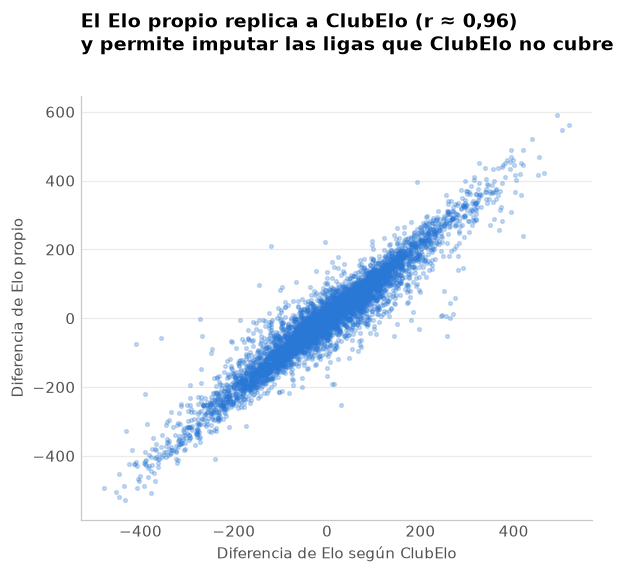

In [14]:
v = partidos[["elo_clubelo_local", "elo_clubelo_visitante", "diferencia_elo"]].dropna()
dif_clubelo = v["elo_clubelo_local"] - v["elo_clubelo_visitante"]
print(f"Correlación de la diferencia de Elo propio vs. ClubElo: r = {dif_clubelo.corr(v['diferencia_elo']):.3f} en {len(v):,} partidos")
fig, ax = plt.subplots(figsize=(6, 5))
muestra = v.sample(6000, random_state=42)
ax.scatter(muestra["elo_clubelo_local"] - muestra["elo_clubelo_visitante"], muestra["diferencia_elo"], s=6, alpha=0.25, color=graficas.ACENTO)
ax.set_xlabel("Diferencia de Elo según ClubElo"); ax.set_ylabel("Diferencia de Elo propio")
ax.set_title("El Elo propio replica a ClubElo (r ≈ 0,96)\ny permite imputar las ligas que ClubElo no cubre")
plt.show()

### 4.4 Agregación (cubos OLAP)

In [15]:
display(pasos[pasos["tecnica"] == "Agregación"])
cubo_lt, cubo_pd, cubo_eq = resultado_etl["cubos"]
display(cubo_lt.tail(5))

,tecnica,paso,antes,despues,afectados,detalle
17,Agregación,Cubo liga × temporada (13 medidas),238854,780,780,Filas del cubo resultante
18,Agregación,Cubo país × década × nivel × resultado,238854,291,291,Filas del cubo resultante
19,Agregación,Cubo equipo × temporada (tabla de posiciones),477708,14215,14215,Filas del cubo resultante


,continente,pais,liga_codigo,liga,nivel,temporada,temporada_inicio,partidos,pct_local,pct_empate,pct_visitante,goles_prom,pct_mas25,margen_casa_prom,acierto_favorito,pct_sorpresas,amarillas_prom,valor_plantilla_prom
775,Europa,Turquía,T1,Süper Lig,1,2022/23,2022,342,45.029,21.345,33.626,3.044,61.988,6.109,53.994,12.780,2.230,53.842
776,Europa,Turquía,T1,Süper Lig,1,2023/24,2023,380,45.526,26.316,28.158,2.795,51.316,6.327,55.789,9.211,2.158,52.531
777,Europa,Turquía,T1,Süper Lig,1,2024/25,2024,314,47.771,24.204,28.025,2.930,54.459,6.368,58.917,10.191,2.283,54.030
778,Europa,Turquía,T1,Süper Lig,1,2025/26,2025,306,42.157,29.085,28.758,2.654,52.941,8.018,53.922,16.340,2.173,55.656
779,Europa,Turquía,T1,Süper Lig,1,2026/27,2026,27,44.444,22.222,33.333,2.815,48.148,7.803,40.741,25.926,1.481,90.435


### 4.5 Resultado del ETL y guardado en Parquet

In [16]:
resumen = resultado_etl["resumen"]
display(pd.Series({k: resumen[k] for k in ["filas_crudas_total", "partidos_limpios", "columnas_limpias", "memoria_limpia_mb",
                                            "peso_parquet_mb", "filas_formato_largo", "equipos", "ligas", "fecha_min", "fecha_max",
                                            "equipos_mapeados_transfermarkt", "partidos_con_valor_mercado"]}).to_frame("valor"))
print("Archivos en data/processed:")
for archivo in sorted(C.DATA_PROCESSED.glob("*")):
    print(f"  {archivo.name:42s} {archivo.stat().st_size / 1e6:7.2f} MB")

,valor
filas_crudas_total,1258950
partidos_limpios,238854
columnas_limpias,87
memoria_limpia_mb,77.090
peso_parquet_mb,21.240
filas_formato_largo,477708
equipos,1222
ligas,38
fecha_min,2000-07-28
fecha_max,2026-09-03


Archivos en data/processed:
  cubo_equipo_temporada.parquet                 0.29 MB
  cubo_liga_temporada.parquet                   0.05 MB
  cubo_pais_decada_nivel.parquet                0.01 MB
  elo_clubelo.parquet                           0.99 MB
  equipos_partido.parquet                       7.48 MB
  estado_equipos.parquet                        0.06 MB
  mapeo_equipos_transfermarkt.parquet           0.03 MB
  partidos_limpios.parquet                     21.24 MB
  predicciones_test.parquet                     2.66 MB
  resumen_etl.json                              0.01 MB


---
## 5. Análisis exploratorio y visualizaciones

Principios de la Actividad 7 aplicados en todas las gráficas:

| Principio | Cómo se aplica |
|---|---|
| Tipo de gráfico | Líneas para tiempo, barras ordenadas para categorías, histograma para distribución, calibración para relación, mapa de calor para dos dimensiones |
| Paleta | Local, Empate y Visitante tienen **siempre** el mismo color (verde aguamarina, naranja, azul); validada para daltonismo (ΔE CVD ≥ 9,2 en todos los pares). El verde tiene contraste < 3:1 sobre blanco, por eso hay **etiquetas directas** |
| Data-ink ratio | Sin marco superior/derecho, rejilla tenue solo en un eje, sin 3D, sin sombras, sin leyenda redundante |
| Títulos con insight | El título dice el hallazgo con su cifra; los ejes van en español con unidades |

### 5.1 Pregunta 1: ¿sigue existiendo la ventaja local?

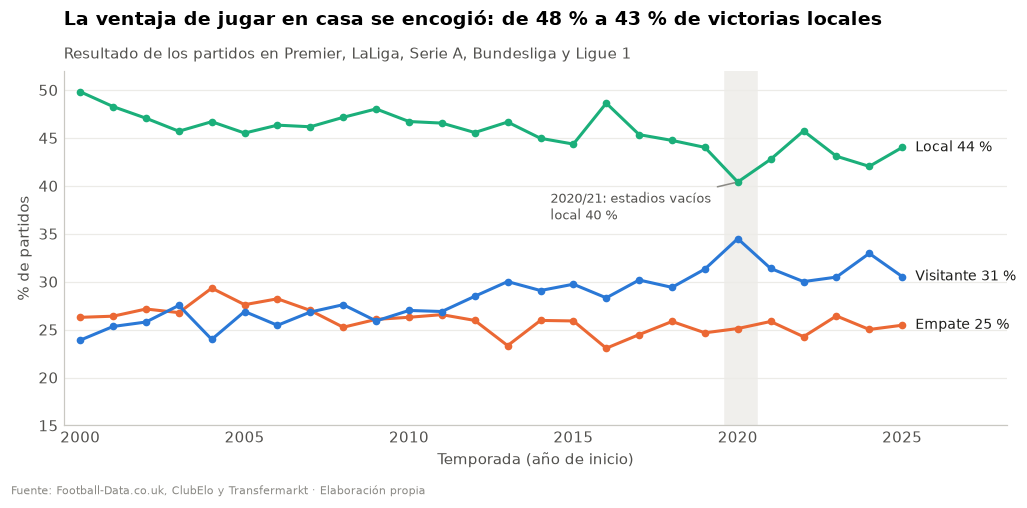

In [17]:
fig, _ = graficas.ventaja_local(partidos); plt.show()

La ventaja local cae de forma sostenida y el **valle de 2020/21** (estadios vacíos) es la mejor evidencia de que buena
parte de la ventaja es el público. Tras el regreso de la afición se recupera, pero no a los niveles de los 2000.

### 5.2 Distribución de goles

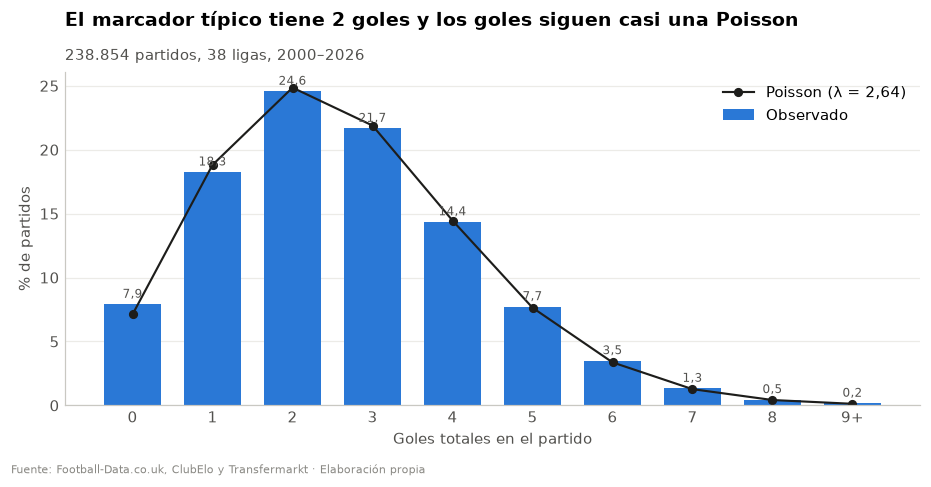

In [18]:
fig, _ = graficas.distribucion_goles(partidos); plt.show()

Los goles siguen casi una Poisson: hay un poco más de 0–0 y de partidos con muchos goles de lo esperado (sobredispersión leve), algo que un modelo de goles debería tener en cuenta.

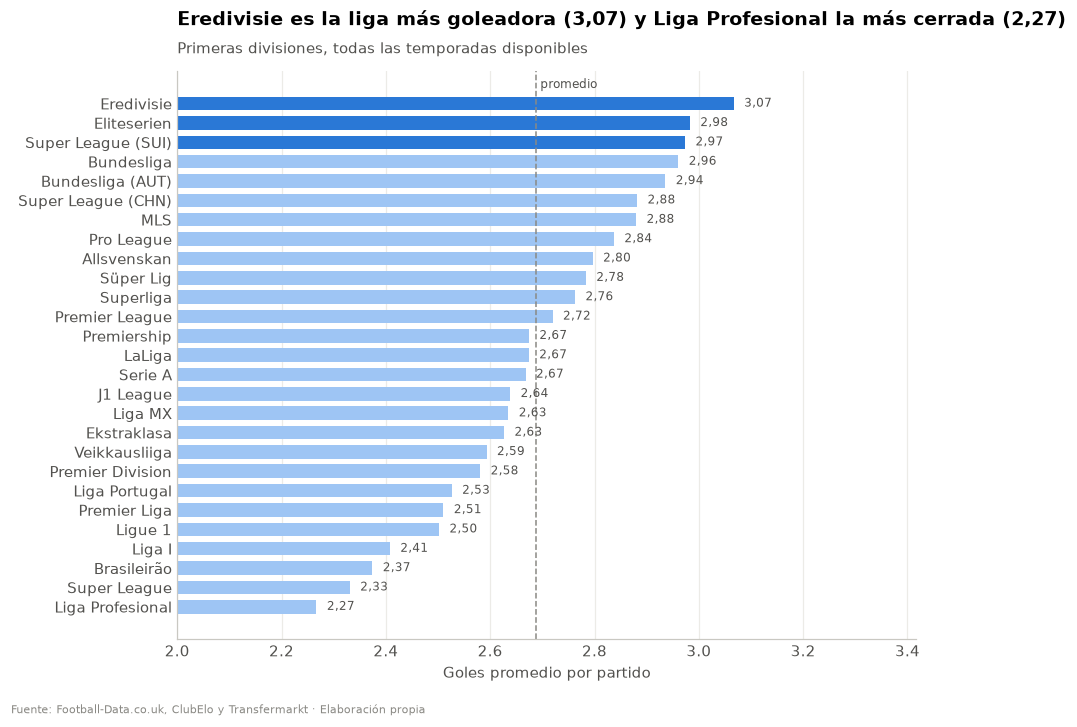

In [19]:
fig, _ = graficas.goles_por_liga(partidos); plt.show()

### 5.3 Pregunta 2: ¿qué tan eficientes son las casas?

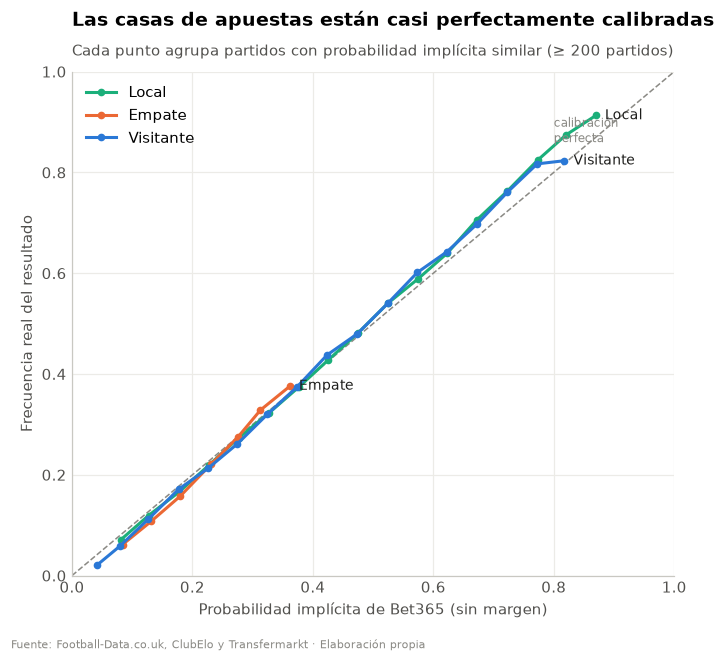

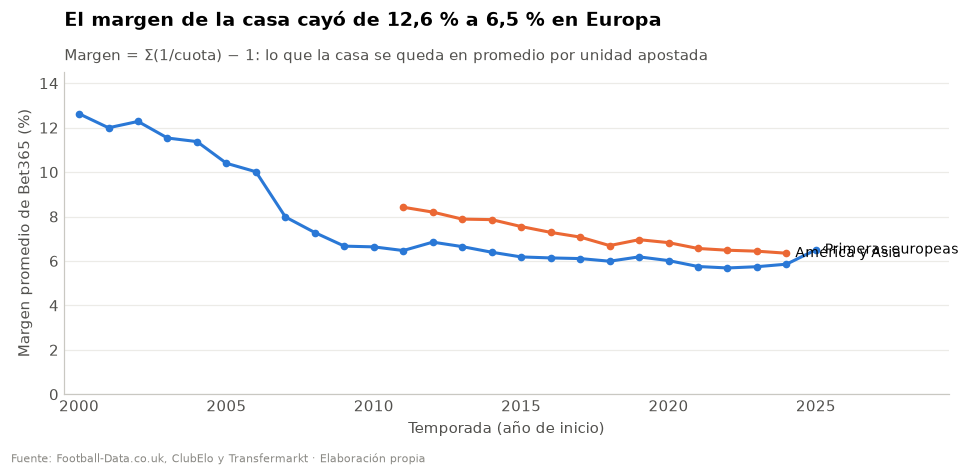

In [20]:
fig, _ = graficas.calibracion_casa(partidos); plt.show()
fig, _ = graficas.margen_casa(partidos); plt.show()

Las probabilidades implícitas de Bet365 caen sobre la diagonal: el mercado está **calibrado**. Y el margen bajó a la
mitad en 25 años; hoy la casa cobra menos, pero sigue cobrando, lo que obliga a cualquier apostador a acertar más que la casa
solo para empatar.

### 5.4 Pregunta 4: ¿pesa el dinero?

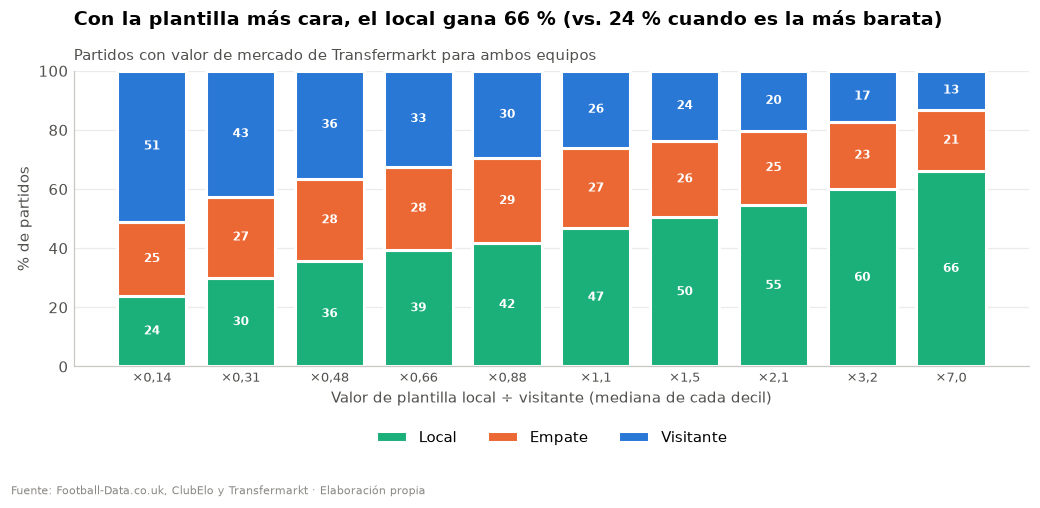

In [21]:
fig, _ = graficas.valor_mercado(partidos); plt.show()

### 5.5 Agregaciones multidimensionales (OLAP)
Los mismos cubos alimentan los filtros del dashboard (panel flotante de *Opciones* y explorador OLAP de la pestaña *Datos*).

**Cubo 1: país × década × nivel × resultado** (mapa de calor):

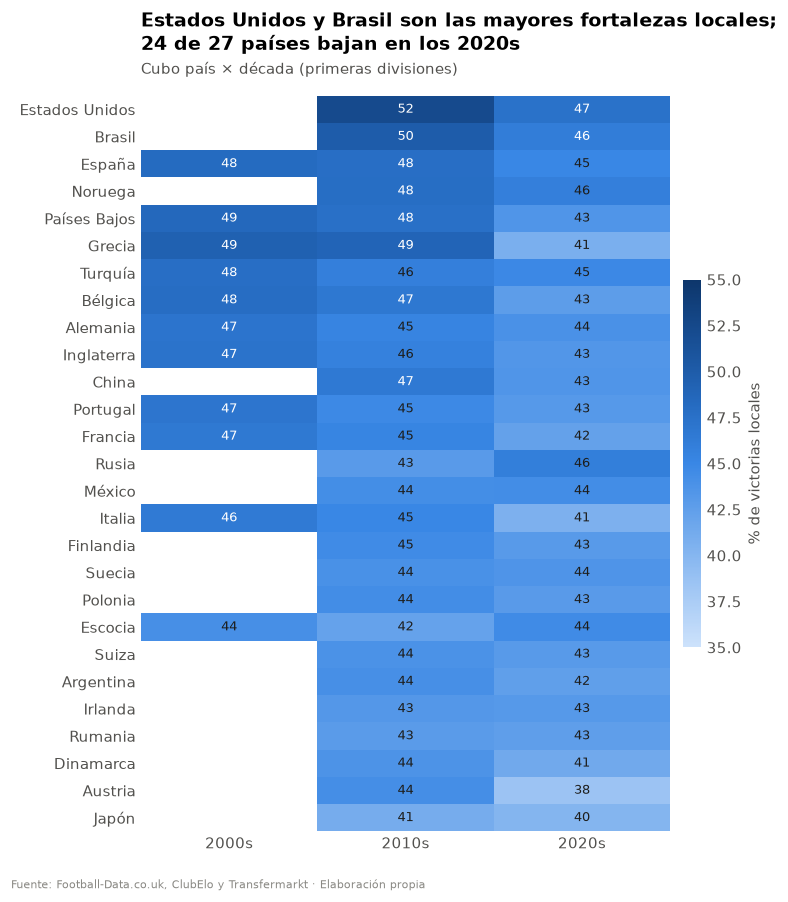

In [22]:
fig, _ = graficas.mapa_pais_decada(partidos); plt.show()

In [23]:
# SLICE: un solo valor de una dimensión (temporada 2025/26) sobre el cubo liga × temporada
slice_2025 = cubo_lt[(cubo_lt["temporada_inicio"] == 2025) & (cubo_lt["nivel"] == 1)]
display(slice_2025[["pais", "liga", "partidos", "pct_local", "pct_empate", "pct_visitante", "goles_prom", "margen_casa_prom", "acierto_favorito"]]
        .sort_values("goles_prom", ascending=False).head(10))

# DICE: varias dimensiones a la vez (España e Inglaterra × niveles 1 y 2 × década 2020s)
dice = cubo_pd[cubo_pd["pais"].isin(["España", "Inglaterra"]) & cubo_pd["nivel"].isin([1, 2]) & (cubo_pd["decada"] == "2020s")]
display(dice.pivot_table(index=["pais", "nivel"], columns="resultado", values="pct_dentro_grupo", observed=True).round(1))

,pais,liga,partidos,pct_local,pct_empate,pct_visitante,goles_prom,margen_casa_prom,acierto_favorito
102,Alemania,Bundesliga,306,43.791,24.510,31.699,3.235,5.528,54.902
657,Países Bajos,Eredivisie,306,44.444,26.144,29.412,3.176,5.681,53.268
380,Francia,Ligue 1,306,46.078,24.510,29.412,2.820,5.630,54.248
210,Escocia,Premiership,228,44.737,26.754,28.509,2.781,7.735,51.316
453,Inglaterra,Premier League,380,42.632,27.368,30.000,2.750,5.515,48.947
314,España,LaLiga,380,48.947,24.474,26.579,2.695,5.615,55.000
697,Portugal,Liga Portugal,306,41.176,27.124,31.699,2.683,7.840,56.536
170,Bélgica,Pro League,311,40.514,25.402,34.084,2.675,7.967,46.945
778,Turquía,Süper Lig,306,42.157,29.085,28.758,2.654,8.018,53.922
426,Grecia,Super League,236,41.102,28.390,30.508,2.568,7.765,50.847


resultado         Empate  Local  Visitante
pais       nivel                          
España     1      26.500 45.000     28.500
           2      28.900 45.200     26.000
Inglaterra 1      23.500 43.400     33.200
           2      25.900 43.000     31.100

In [24]:
# DRILL-DOWN: continente → país → liga (y ROLL-UP en sentido contrario) sobre los partidos limpios
for nivel_jerarquia in (["continente"], ["continente", "pais"], ["continente", "pais", "liga"]):
    tabla = (partidos.groupby(nivel_jerarquia, observed=True)
             .agg(partidos=("resultado", "size"), goles=("total_goles", "mean"),
                  pct_local=("resultado", lambda s: (s == "Local").mean() * 100)).round(2))
    print("Nivel:", " → ".join(nivel_jerarquia), f"({len(tabla)} grupos)")
    display(tabla.sort_values("partidos", ascending=False).head(6))

Nivel: continente (3 grupos)


,partidos,goles,pct_local
continente,,,
Europa,212729,2.650,44.440
América,19492,2.540,46.660
Asia,6633,2.730,42.410


Nivel: continente → pais (27 grupos)


partidos  goles  pct_local
continente pais                                  
Europa     Inglaterra     58958  2.630     43.660
           España         20411  2.500     45.820
           Italia         19733  2.540     43.780
           Escocia        18182  2.780     42.980
           Francia        18099  2.430     44.600
           Alemania       15331  2.880     45.270

Nivel: continente → pais → liga (38 grupos)


partidos  goles  pct_local
continente pais       liga                                      
Europa     Inglaterra Championship       14206  2.570     43.690
                      League One         13819  2.620     43.750
                      League Two         13377  2.550     42.490
           España     LaLiga 2           10992  2.340     44.650
           Italia     Serie B            10321  2.420     43.230
           Inglaterra Premier League      9810  2.720     45.690

In [25]:
# Cubo 3: equipo × temporada (tabla de posiciones) — líderes de las 5 grandes ligas 2025/26
lideres = cubo_eq[(cubo_eq["temporada_inicio"] == 2025) & (cubo_eq["posicion"] == 1) & cubo_eq["liga_codigo"].isin(["E0", "SP1", "I1", "D1", "F1"])]
display(lideres[["liga", "equipo", "partidos", "victorias", "empates", "derrotas", "gf", "gc", "puntos", "valor_plantilla_meur"]])

,liga,equipo,partidos,victorias,empates,derrotas,gf,gc,puntos,valor_plantilla_meur
862,Premier League,Arsenal,38,26,7,5,71.000,27.000,85,"1,100.500"
1323,LaLiga,Barcelona,38,31,1,6,95.000,36.000,94,"1,065.000"
1481,Bundesliga,Bayern Munich,34,28,5,1,122.000,36.000,89,845.000
6338,Serie A,Inter,38,27,6,5,89.000,35.000,87,671.800
9684,Ligue 1,Paris SG,34,24,4,6,74.000,29.000,76,"1,045.500"


---
## 6. Modeling

### 6.1 Preparación de variables y cómo se evitó la fuga de información
- **Solo información previa al pitazo:** se excluyen goles, tiros, tarjetas, córners, resultado al descanso y las columnas
  `C_*`. Las variables de forma usan `shift(1)`, el Elo es el previo al partido y el valor de plantilla es el del inicio
  de la temporada.
- **Partición temporal, nunca aleatoria:** entrenamiento hasta 30/06/2022, validación 2022/23 y prueba desde el
  01/07/2023. Barajar mezclaría partidos del futuro en el entrenamiento.
- **Preprocesamiento dentro de un `Pipeline`:** imputación (mediana + indicador de faltante), escalado y codificación
  (one-hot u ordinal de la liga) se ajustan **solo** con entrenamiento.
- **Selección sin mirar prueba:** el mejor algoritmo se elige por log-loss en validación y el umbral de empates también
  se elige en validación, con el modelo que no vio validación. Después se re-entrena con entrenamiento + validación.

### 6.2 Modelos
Dos líneas base y tres algoritmos, cada uno con dos conjuntos de variables:
**sin cuotas** (fútbol puro: Elo, forma, valor de plantilla, descanso, liga) y **con cuotas** (lo anterior más las
probabilidades del mercado). Comparar ambos mide cuánto sabe el mercado más allá de los datos públicos.

| Modelo | Por qué |
|---|---|
| Regresión logística multinomial | Lineal, interpretable y bien calibrada |
| Random Forest | No lineal y robusto, poco ajuste de hiperparámetros |
| LightGBM | Boosting de gradiente con parada temprana en validación; maneja faltantes de forma nativa |

El entrenamiento completo tarda ≈ 4–5 minutos (Random Forest es el más lento).

In [26]:
t0 = time.perf_counter()
metricas = modelo.ejecutar_modelado(partidos)
print(f"Modelado en {time.perf_counter() - t0:.1f} s")

Entrenamiento 194,274 | validación 12,334 | prueba 29,190


  [sin_cuotas] Regresión logística  val logloss=1.0129  test logloss=1.0206 acc=0.4881 f1m=0.3595  (26.5 s)


  [sin_cuotas] Random Forest        val logloss=1.0138  test logloss=1.0190 acc=0.4889 f1m=0.3534  (69.1 s)


  [sin_cuotas] LightGBM             val logloss=1.0116  test logloss=1.0186 acc=0.4901 f1m=0.3594  (29.0 s)


  [con_cuotas] Regresión logística  val logloss=0.9962  test logloss=1.0028 acc=0.5029 f1m=0.3792  (38.6 s)


  [con_cuotas] Random Forest        val logloss=0.9969  test logloss=1.0018 acc=0.5027 f1m=0.3765  (93.9 s)


  [con_cuotas] LightGBM             val logloss=0.9966  test logloss=1.0021 acc=0.5034 f1m=0.3818  (31.7 s)


Mejor con cuotas: Regresión logística | mejor sin cuotas: LightGBM | criterios: {'f1_macro_vs_ingenua_pct': 119.8, 'cumple_f1_10pct': True, 'logloss_modelo_vs_casa': -0.0001, 'cumple_logloss_casa': True, 'accuracy_sin_cuotas_vs_casa_pp': -1.19, 'roi_positivo': True}
Modelado completo en 335.3 s
Modelado en 335.3 s


---
## 7. Evaluation
### 7.1 Métricas en prueba frente a las líneas base

In [27]:
filas = []
for nombre, r in metricas["lineas_base"].items():
    filas.append({"modelo": f"LÍNEA BASE · {nombre}", **{k: r["prueba"][k] for k in ["accuracy", "balanced_accuracy", "f1_macro", "log_loss", "brier", "roc_auc_ovr"]}})
for conjunto, res in metricas["resultados"].items():
    for nombre, r in res.items():
        if not nombre.startswith("_"):
            filas.append({"modelo": f"{nombre} · {conjunto}", **{k: r["prueba"][k] for k in ["accuracy", "balanced_accuracy", "f1_macro", "log_loss", "brier", "roc_auc_ovr"]}})
tabla_metricas = pd.DataFrame(filas).set_index("modelo")
display(tabla_metricas.style.format("{:.4f}").highlight_min(subset=["log_loss", "brier"], color="#cdeee0").highlight_max(subset=["accuracy", "f1_macro"], color="#cdeee0"))
for conjunto in ["con_cuotas", "sin_cuotas"]:
    m = metricas["resultados"][conjunto]["_mejor"]
    print(f"Mejor {conjunto}: {m['modelo']} | umbral de empate {m['umbral_empate']} | F1 macro con umbral {m['prueba_con_umbral']['f1_macro']:.4f}")
display(pd.Series(metricas["criterios_exito"]).to_frame("criterios de éxito"))

,accuracy,balanced_accuracy,f1_macro,log_loss,brier,roc_auc_ovr
modelo,,,,,,
LÍNEA BASE · Siempre local,0.4344,0.3333,0.2019,1.0759,0.6510,0.5000
LÍNEA BASE · Favorito de la casa,0.5019,0.4336,0.3710,1.0029,0.5999,0.6489
Regresión logística · sin_cuotas,0.4881,0.4197,0.3595,1.0206,0.6119,0.6266
Random Forest · sin_cuotas,0.4889,0.4163,0.3534,1.0190,0.6109,0.6286
LightGBM · sin_cuotas,0.4901,0.4197,0.3594,1.0186,0.6106,0.6293
Regresión logística · con_cuotas,0.5029,0.4367,0.3792,1.0028,0.5999,0.6482
Random Forest · con_cuotas,0.5027,0.4364,0.3765,1.0018,0.5993,0.6495
LightGBM · con_cuotas,0.5034,0.4373,0.3818,1.0021,0.5995,0.6490


Mejor con_cuotas: Regresión logística | umbral de empate 0.295 | F1 macro con umbral 0.4438
Mejor sin_cuotas: LightGBM | umbral de empate 0.28 | F1 macro con umbral 0.4326


,criterios de éxito
f1_macro_vs_ingenua_pct,119.800
cumple_f1_10pct,True
logloss_modelo_vs_casa,-0.000
cumple_logloss_casa,True
accuracy_sin_cuotas_vs_casa_pp,-1.190
roi_positivo,True


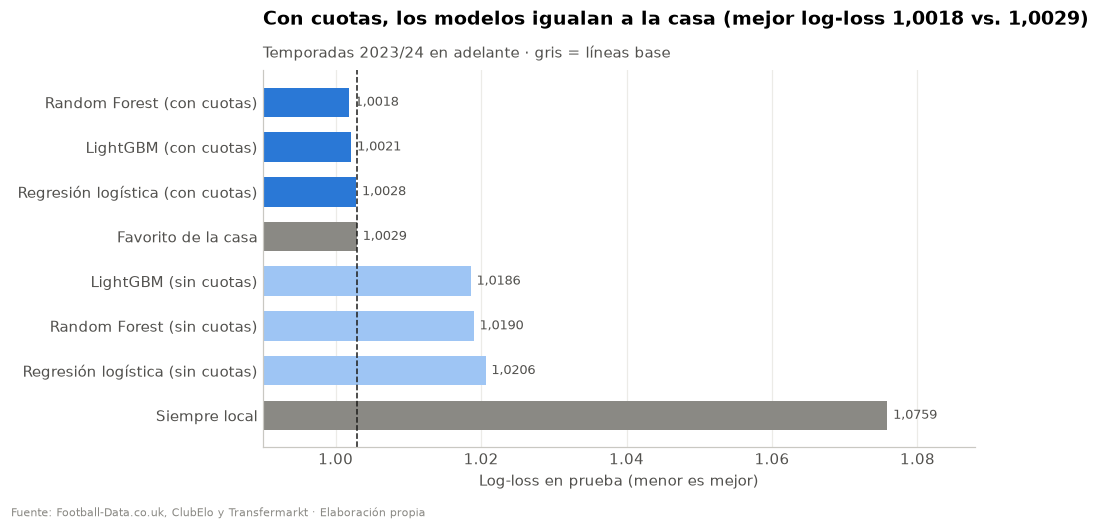

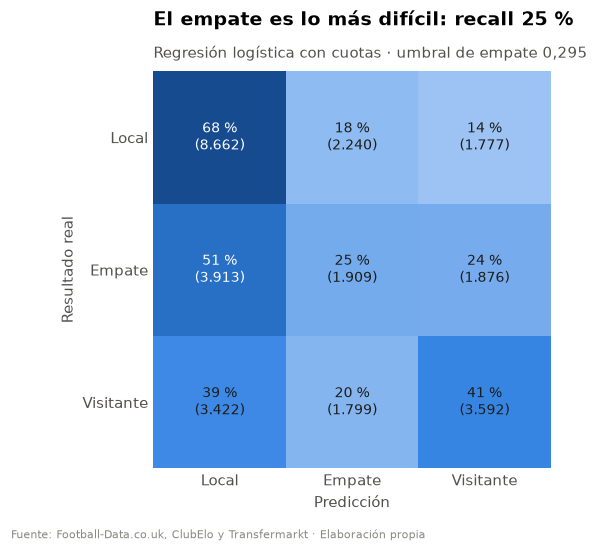

,precision,recall,f1,soporte
Local,0.541,0.683,0.604,"12,679.000"
Empate,0.321,0.248,0.280,"7,698.000"
Visitante,0.496,0.408,0.447,"8,813.000"


In [28]:
fig, _ = graficas.comparacion_modelos(metricas); plt.show()
fig, _ = graficas.matriz_confusion(metricas); plt.show()
mejor = metricas["resultados"]["con_cuotas"]["_mejor"]
display(pd.DataFrame(mejor["prueba_con_umbral"]["por_clase"]).T)

**Lectura de las métricas.**
- **Criterio 1 (F1 macro ≥ +10 % sobre la ingenua): cumplido de sobra.** "Siempre local" tiene F1 macro ≈ 0,20 porque
  nunca acierta empates ni visitantes.
- **Criterio 2 (log-loss ≤ casa): cumplido, por un pelo.** Con cuotas, los tres algoritmos quedan prácticamente empatados
  con el mercado (diferencias en la cuarta cifra decimal): el mercado ya incorpora casi toda la información pública.
- **Sin cuotas**, el mejor modelo queda ~1 punto de accuracy por debajo de la casa usando solo datos públicos y gratuitos.
- La **accuracy ronda el 50 %**: el fútbol es un deporte de pocos goles y mucha varianza, y ningún modelo (ni la casa)
  supera ~52 % en un dataset tan amplio.
- El **empate** es la clase difícil: casi nunca es el resultado más probable. El umbral ajustado en validación sube su
  recall de ~0 % a ~25 % y mejora el F1 macro, a cambio de un poco de accuracy.

### 7.2 Interpretación en lenguaje de negocio

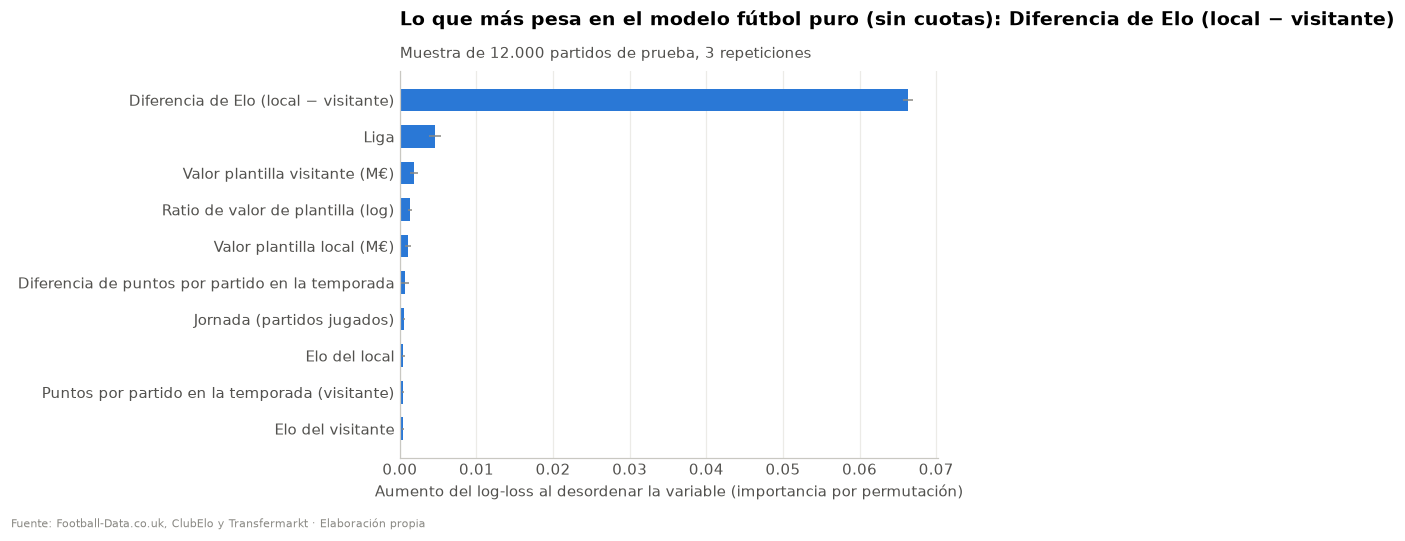

,etiqueta,importancia,desviacion
0,Log-odds casa (local vs. visitante),0.167,0.001
1,Diferencia de puntos por partido en la temporada,0.004,0.000
2,Prob. implícita casa: empate,0.003,0.000
3,Puntos por partido en la temporada (visitante),0.002,0.000
4,Puntos por partido en la temporada (local),0.001,0.001
5,Valor plantilla visitante (M€),0.001,0.000
6,Valor plantilla local (M€),0.001,0.000
7,Diferencia de forma (5 partidos),0.001,0.000


In [29]:
fig, _ = graficas.importancia(metricas, "sin_cuotas"); plt.show()
display(pd.DataFrame(metricas["importancias"]["con_cuotas"]).head(8)[["etiqueta", "importancia", "desviacion"]])

- **En fútbol puro, la diferencia de Elo es la variable reina**: saber cuánto mejor es un equipo, resumiendo todo su
  historial, explica más que cualquier racha. Le siguen la liga (cada una tiene distinta tasa de empates y de localía) y el
  valor de plantilla (fichajes que el Elo aún no refleja).
- **La forma de los últimos 5 partidos casi no aporta** una vez se conoce el Elo: las rachas se sobrevaloran.
- **Con cuotas, el log-odds de la casa concentra casi todo**: el mercado ya resume Elo, forma, lesiones y noticias. Lo
  que el modelo añade encima es pequeño, pero existe (ver la simulación).

### 7.3 Pregunta 5: ¿alcanza para ganar dinero?
Estrategia de **apuestas de valor** sobre las temporadas de prueba: apostar 1 unidad cuando `p_modelo × cuota − 1 > umbral`,
con la mejor cuota del mercado. La **estrategia de control** usa las probabilidades de la propia casa: si también ganara,
la ventaja vendría solo de buscar la mejor cuota y no del modelo.

,apuestas,aciertos,tasa_acierto,cuota_media,beneficio_unidades,roi,max_caida
sin_cuotas,"22,519.000","7,099.000",0.315,3.671,-843.320,-0.037,975.110
con_cuotas,"7,847.000","2,481.000",0.316,3.687,107.300,0.014,100.350
casa,"2,983.000",566.000,0.190,6.141,-103.300,-0.035,233.690


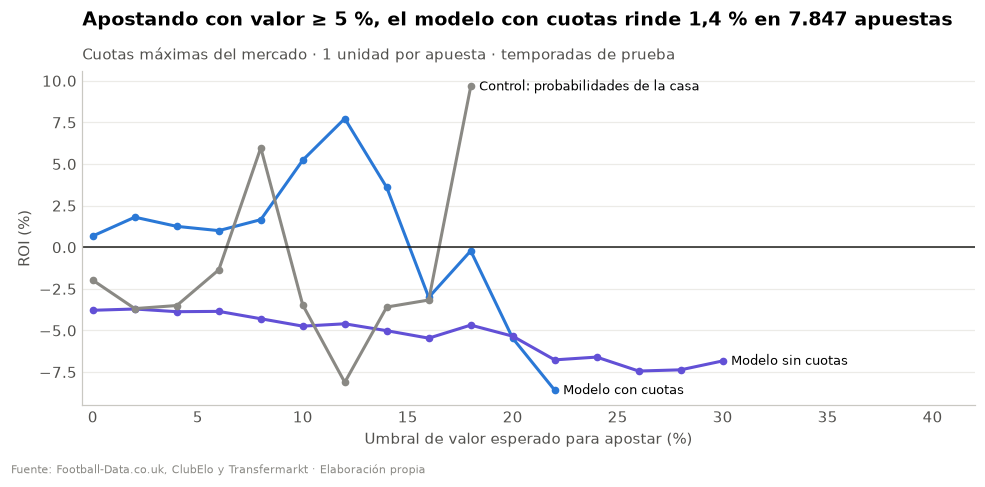

In [30]:
display(pd.DataFrame({k: v["umbral_5pct"] for k, v in metricas["simulacion"].items()}).T
        [["apuestas", "aciertos", "tasa_acierto", "cuota_media", "beneficio_unidades", "roi", "max_caida"]])
fig, _ = graficas.curva_roi(metricas); plt.show()

El modelo **con cuotas** obtiene un ROI levemente positivo con umbrales bajos, mientras el control (probabilidades de la
casa) y el modelo sin cuotas pierden. Es decir, el modelo sí añade algo de información útil al mercado, **pero el margen es
pequeño y volátil**: con umbrales altos se hacen pocas apuestas y el ROI salta por pura varianza. En la práctica, además, las
casas limitan las cuentas ganadoras y las cuotas máximas no siempre están disponibles: es una prueba de concepto, no un
sistema para apostar.

### 7.4 Respuestas a las preguntas de negocio

In [31]:
grandes = partidos[partidos["liga_codigo"].isin(["E0", "SP1", "I1", "D1", "F1"]) & (partidos["temporada_inicio"] <= 2025)]
local_por_temporada = grandes.groupby("temporada_inicio")["resultado"].apply(lambda s: (s == "Local").mean() * 100)
casa = metricas["lineas_base"]["Favorito de la casa"]["prueba"]
mejor_con = metricas["resultados"]["con_cuotas"]["_mejor"]
mejor_sin = metricas["resultados"]["sin_cuotas"]["_mejor"]
r_con = metricas["resultados"]["con_cuotas"][mejor_con["modelo"]]["prueba"]
r_sin = metricas["resultados"]["sin_cuotas"][mejor_sin["modelo"]]["prueba"]
europa = partidos[(partidos["nivel"] == 1) & (partidos["continente"] == "Europa")].groupby("temporada_inicio")["margen_casa"].mean() * 100
respuestas = [
    ("1. ¿Sigue la ventaja local?", f"Sí, pero menor: {local_por_temporada.loc[2000:2002].mean():.1f} % → {local_por_temporada.loc[2023:2025].mean():.1f} % de victorias locales; {local_por_temporada.loc[2020]:.1f} % con estadios vacíos."),
    ("2. ¿Son eficientes las casas?", f"Muy: calibradas casi sobre la diagonal y con un margen que bajó de {europa.iloc[0]:.1f} % a {europa.loc[:2025].iloc[-1]:.1f} %."),
    ("3. ¿Qué explica el resultado?", f"Ante todo la diferencia de Elo; luego la liga y el valor de plantilla. La forma reciente aporta poco."),
    ("4. ¿Pesa el dinero?", "Sí: el decil con la plantilla relativa más cara gana ~66 % como local vs. ~24 % del decil más barato."),
    ("5. ¿Se iguala a la casa? ¿Hay ROI?", f"Con cuotas, log-loss {r_con['log_loss']:.4f} vs. {casa['log_loss']:.4f} (igual). Sin cuotas, {r_sin['accuracy']*100:.1f} % vs. {casa['accuracy']*100:.1f} % de accuracy. ROI con valor ≥ 5 %: {metricas['simulacion']['con_cuotas']['umbral_5pct']['roi']*100:+.2f} %, pequeño y volátil."),
]
display(pd.DataFrame(respuestas, columns=["pregunta", "respuesta"]).style.hide(axis="index"))

pregunta,respuesta
1. ¿Sigue la ventaja local?,"Sí, pero menor: 48.4 % → 43.0 % de victorias locales; 40.4 % con estadios vacíos."
2. ¿Son eficientes las casas?,Muy: calibradas casi sobre la diagonal y con un margen que bajó de 12.6 % a 6.5 %.
3. ¿Qué explica el resultado?,Ante todo la diferencia de Elo; luego la liga y el valor de plantilla. La forma reciente aporta poco.
4. ¿Pesa el dinero?,Sí: el decil con la plantilla relativa más cara gana ~66 % como local vs. ~24 % del decil más barato.
5. ¿Se iguala a la casa? ¿Hay ROI?,"Con cuotas, log-loss 1.0028 vs. 1.0029 (igual). Sin cuotas, 49.0 % vs. 50.2 % de accuracy. ROI con valor ≥ 5 %: +1.37 %, pequeño y volátil."


---
## 8. Insights en MongoDB
Se construye el documento de análisis con la estructura de la Actividad 1, ampliada con el modelo (`metadata`,
`calidad_datos`, `estadisticas_descriptivas`, `agregaciones`, `modelo`, `insights`, `visualizaciones_generadas`,
`recomendaciones`). Todas las cifras de los insights se calculan a partir de los datos; ninguna está escrita a mano.

In [32]:
visualizaciones = graficas.generar_todas(partidos, metricas)
documento = mongo_insights.construir_documento(partidos, metricas, resultado_etl["resumen"], visualizaciones)
print("Secciones:", list(documento.keys()))
print(f"{len(documento['insights'])} insights | {len(documento['recomendaciones'])} recomendaciones | {len(visualizaciones)} visualizaciones")
mongo_insights.guardar(documento)
cliente, coleccion = mongo_insights.conectar()
print("Documentos en la colección:", coleccion.count_documents({}))

Secciones: ['_id', 'metadata', 'calidad_datos', 'estadisticas_descriptivas', 'agregaciones', 'modelo', 'insights', 'visualizaciones_generadas', 'recomendaciones']
8 insights | 4 recomendaciones | 11 visualizaciones
Documentos en la colección: 1


### 8.1 Consultas a MongoDB

In [33]:
# Consulta 1: recuperar las métricas del modelo y de las líneas base (proyección)
q1 = coleccion.find_one({"_id": mongo_insights.DOC_ID}, {"_id": 0, "modelo.algoritmo": 1, "modelo.metricas": 1, "modelo.linea_base": 1})
print("Algoritmo:", q1["modelo"]["algoritmo"])
display(pd.DataFrame({"modelo": q1["modelo"]["metricas"], **q1["modelo"]["linea_base"]}).T[["accuracy", "f1_macro", "log_loss"]])

Algoritmo: Regresión logística


,accuracy,f1_macro,log_loss
modelo,0.503,0.379,1.003
Siempre local,0.434,0.202,1.076
Favorito de la casa,0.502,0.371,1.003


In [34]:
# Consulta 2: filtrar insights por tema ($unwind + $match + $project)
q2 = list(coleccion.aggregate([
    {"$match": {"_id": mongo_insights.DOC_ID}}, {"$unwind": "$insights"},
    {"$match": {"insights.tema": {"$in": ["Modelo", "Apuestas"]}}},
    {"$project": {"_id": 0, "tema": "$insights.tema", "titulo": "$insights.titulo", "valor": "$insights.valor"}}]))
display(pd.DataFrame(q2))

,tema,titulo,valor
0,Modelo,El modelo con cuotas iguala a la casa; sin cuo...,-0.000
1,Modelo,La diferencia de Elo es la variable reina del ...,0.066
2,Apuestas,Ganarle a la casa es posible solo en el margen...,0.014


In [35]:
# Consulta 3: las 5 variables más importantes ordenadas ($unwind + $sort + $limit)
q3 = list(coleccion.aggregate([
    {"$match": {"_id": mongo_insights.DOC_ID}}, {"$unwind": "$modelo.variables_importantes_sin_cuotas"},
    {"$sort": {"modelo.variables_importantes_sin_cuotas.importancia": -1}}, {"$limit": 5},
    {"$project": {"_id": 0, "variable": "$modelo.variables_importantes_sin_cuotas.etiqueta",
                  "importancia": "$modelo.variables_importantes_sin_cuotas.importancia"}}]))
display(pd.DataFrame(q3))

,variable,importancia
0,Diferencia de Elo (local − visitante),0.066
1,Liga,0.005
2,Valor plantilla visitante (M€),0.002
3,Ratio de valor de plantilla (log),0.001
4,Valor plantilla local (M€),0.001


In [36]:
# Consulta 4: conteo de insights por tema ($group) y problemas de calidad más frecuentes
display(pd.DataFrame(list(coleccion.aggregate([
    {"$match": {"_id": mongo_insights.DOC_ID}}, {"$unwind": "$insights"},
    {"$group": {"_id": "$insights.tema", "cantidad": {"$sum": 1}}}, {"$sort": {"cantidad": -1}}]))))
display(pd.DataFrame(mongo_insights.consultas_ejemplo(coleccion)["4_problemas_calidad_mas_frecuentes"]))

,_id,cantidad
0,Modelo,2
1,Mercado de apuestas,1
2,Valor de mercado,1
3,Ligas,1
4,Apuestas,1
5,Ventaja local,1
6,Empates,1


,problema,registros
0,"Estadísticas de partido faltantes (tiros, falt...",116375
1,Columnas de clúster C_* del autor del espejo (...,112602
2,Elo de ClubElo faltante,98144
3,Valoraciones con club 'Unknown',3199
4,Cuotas Bet365 faltantes,3042


**Insights y recomendaciones guardados** (leídos de vuelta desde MongoDB):

In [37]:
guardado = coleccion.find_one({"_id": mongo_insights.DOC_ID}, {"insights": 1, "recomendaciones": 1})
for ins in guardado["insights"]:
    display(Markdown(f"**{ins['id']}. {ins['titulo']}** *({ins['tema']})* — {ins['texto']}"))
for r in guardado["recomendaciones"]:
    display(Markdown(f"**R{r['id']} · {r['dirigida_a']}:** {r['texto']}"))

**1. La ventaja de jugar en casa se está encogiendo** *(Ventaja local)* — En las 5 grandes ligas el local ganaba el 48,4 % de los partidos a inicios de los 2000 y hoy gana el 43,0 %. En 2020/21, con estadios vacíos por la COVID-19, cayó a 40,4 %: el público explica buena parte de la ventaja.

**2. Las casas están calibradas y cobran cada vez menos margen** *(Mercado de apuestas)* — Cuando Bet365 da 60 % a un resultado, ocurre cerca del 60 % de las veces (diagrama de calibración). Su margen en primeras europeas bajó de 12,6 % (2000) a 6,5 % (2025): el mercado es más eficiente y competitivo.

**3. El modelo con cuotas iguala a la casa; sin cuotas queda cerca** *(Modelo)* — En 29.190 partidos de prueba (2023/24 en adelante), Regresión logística con cuotas logra log-loss 1,0028 frente a 1,0029 de la casa y 1,0759 de la línea base ingenua. El modelo de fútbol puro (LightGBM) acierta 49,0 % vs. 50,2 % de la casa: solo con datos públicos se llega a 1,2 pp del mercado.

**4. La diferencia de Elo es la variable reina del fútbol puro** *(Modelo)* — En el modelo sin cuotas, 'Diferencia de Elo (local − visitante)' es por lejos la variable más importante (importancia por permutación 0,0663), seguida de 'Liga' y 'Valor plantilla visitante (M€)'. La forma reciente aporta poco una vez se conoce el Elo.

**5. La plata sí juega: el valor de plantilla separa resultados** *(Valor de mercado)* — Cuando el local tiene la plantilla relativamente más cara (decil superior) gana el 66,1 % de las veces; cuando tiene la más barata, solo el 23,9 %. El valor de Transfermarkt enriquece el Elo con información de calidad individual.

**6. El empate es el resultado más difícil de predecir** *(Empates)* — El 26,5 % de los partidos termina empatado, pero casi nunca es el resultado más probable. Con el umbral de decisión ajustado (predecir empate si p ≥ 0,295) el recall de empates sube a 24,8 % y el F1 macro pasa de 0,379 a 0,444.

... (2 outputs left out)

**R1 · Apostadores:** No apostar con las cuotas de una sola casa: sin comparar cuotas el ROI esperado es negativo (margen ≈ 6,5 %). Si se apuesta, hacerlo solo con valor esperado positivo, la mejor cuota disponible y montos fijos pequeños, porque las rachas negativas son largas.

**R2 · Clubes y analistas:** Usar el Elo (propio o de ClubElo) y el valor de plantilla como base de cualquier pronóstico de puntos o de presupuesto deportivo; la forma de los últimos 5 partidos aporta poco y suele sobrevalorarse.

**R3 · Equipo de datos:** Re-entrenar el modelo cada temporada: la ventaja local cambió (COVID, VAR) y un modelo entrenado con los 2000 sobreestima al local. Vigilar la calibración con el diagrama de la pestaña Modelo.

**R4 · Equipo de datos:** Para mejorar el empate, probar un modelo específico de goles (Poisson bivariado o Dixon-Coles) y variables de estilo (tiros, xG) cuando la fuente las tenga completas.

---
## 9. Reporte PDF generado automáticamente
`reporte_pdf.generar()` **lee el documento desde MongoDB** y arma con ReportLab: portada, resumen del dataset, problemas de
calidad y pasos ETL, tablas de agregación, gráficas de EDA, resultados del modelo, simulación, insights y recomendaciones.

PDF: reports/reporte_futbol_apuestas.pdf (1.20 MB)
Páginas: 14


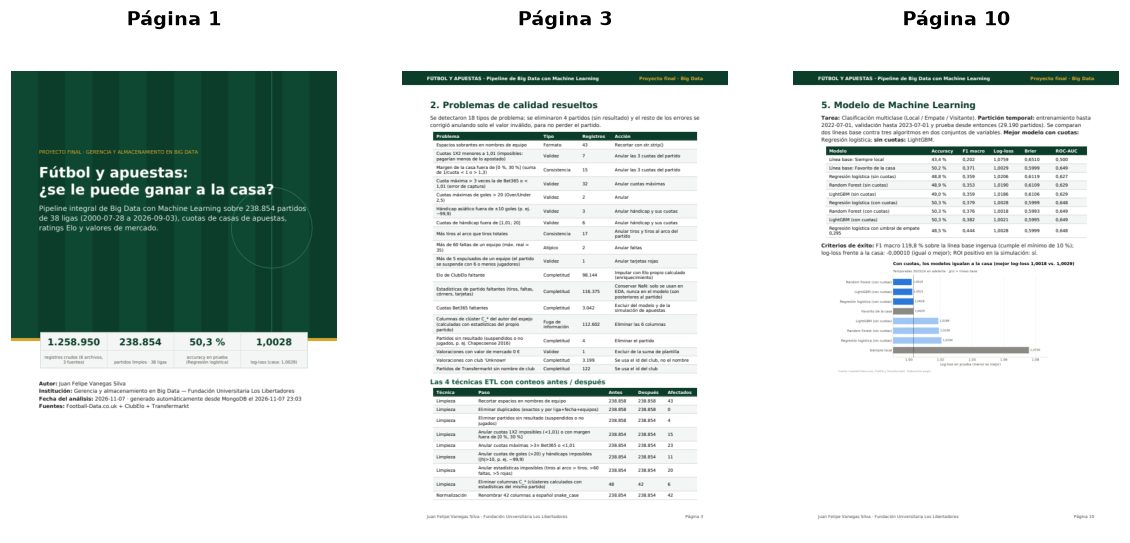

In [38]:
documento_mongo = mongo_insights.leer()
ruta_pdf = reporte_pdf.generar(documento_mongo)
print(f"PDF: {ruta_pdf.relative_to(RAIZ)} ({ruta_pdf.stat().st_size / 1e6:.2f} MB)")
import pypdfium2 as pdfium
pdf = pdfium.PdfDocument(str(ruta_pdf))
print("Páginas:", len(pdf))
fig, ejes = plt.subplots(1, 3, figsize=(13, 6))
for eje, pagina in zip(ejes, [0, 2, 9 if len(pdf) > 9 else len(pdf) - 1]):
    eje.imshow(pdf[pagina].render(scale=0.9).to_pil()); eje.axis("off"); eje.set_title(f"Página {pagina + 1}", loc="center")
plt.show()

---
## 10. Conclusiones y aprendizajes

1. **El mercado de apuestas es muy eficiente.** Sus probabilidades están calibradas y un modelo con datos públicos solo
   logra igualarlo cuando *usa* sus cuotas. Sin ellas, se queda a ~1 punto de accuracy, lo cual es meritorio para datos gratuitos.
2. **La ventaja local existe pero se encoge**, y los estadios vacíos de 2020/21 demostraron que la afición es buena parte de ella.
3. **Elo y dinero explican el fútbol mejor que las rachas.** La forma reciente casi no aporta encima del Elo.
4. **Ganarle a la casa es posible solo en el margen**, con la mejor cuota disponible y aceptando mucha varianza.
5. **Integrar varias fuentes fue el mayor reto de ETL:** homologar nombres de equipos sin una llave común se resolvió con
   evidencia de partidos (liga + fecha + marcador) en lugar de comparar textos.

**Qué funcionó:** la partición temporal y la disciplina anti-fuga (los resultados de prueba son creíbles), el Elo propio
para imputar ligas sin ClubElo y la arquitectura de tres servicios que separa procesamiento, base de datos y app.

**Qué no funcionó o haría distinto:** predecir empates sigue siendo débil (probaría un modelo de goles tipo Dixon-Coles);
las estadísticas de juego (tiros, xG) faltan en la mitad de las ligas y no se pudieron usar como forma reciente; y con más
tiempo agregaría cuotas de cierre y apertura para medir el movimiento del mercado.

Los problemas de infraestructura encontrados (CDN que bloquea `Python-urllib`, servidor que corta la conexión, sockets
huérfanos de Docker Desktop, Spark sin sockets AF_UNIX, `log_loss` con columnas desordenadas…) están diagnosticados paso a paso en el **README**.

In [39]:
# Cierre de conexiones a la base de datos
cliente.close()
print("Conexión a MongoDB cerrada. Notebook completo.")

Conexión a MongoDB cerrada. Notebook completo.
